# MedIR: Meningkatkan Retrieval Biomedis pada NFCorpus

**Ringkasan hasil (split test, 323 query)**

| Metrik | BM25 (baseline) | Hybrid tanpa label | Model akhir | Kenaikan akhir vs BM25 |
|---|---|---|---|---|
| Precision@5 | 0,309 | 0,350 | **0,437** | +41% |
| Precision@10 | 0,241 | 0,283 | **0,373** | +55% |
| nDCG@10 | 0,329 | 0,376 | **0,467** | +42% |

**Aturan eksperimen supaya adil**
- `train`: sumber label untuk fitur (expansion, kNN, co-citation).
- `dev`: memilih semua parameter dan bobot penggabungan.
- `test`: hanya untuk pelaporan. Tidak ada keputusan yang diambil dari angka test.

Urutan skrip pendukung: `download_data.py`, `00_eda.py`, `01_baseline.py`, `02_train_label_methods.py`, `check_leakage.py`, `03_dense.py`, `05_final.py`, `06_error_analysis.py`.

## 1. Memuat dan memvalidasi data

In [1]:
import json, pickle
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
from IPython.display import Image, display
from common import *
from label_signals import LabelSignals, norm

corpus, queries = load_corpus(), load_queries()
doc_ids = list(corpus.index)
docs = doc_strings(corpus)
qrels = {s: load_qrels(s) for s in ('train', 'dev', 'test')}
FIG = RESULTS / 'figures'
print('dokumen', len(corpus), '| query', len(queries))
print('ID dokumen qrels yang hilang:', sum(d not in corpus.index for q in qrels.values() for v in q.values() for d in v))
print('ID query qrels yang hilang  :', sum(k not in queries for q in qrels.values() for k in q))
corpus.head(3)

dokumen 3633 | query 3237


ID dokumen qrels yang hilang: 0
ID query qrels yang hilang  : 0


,title,text
_id,,
MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an..."
MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...
MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...


**Interpretasi:** Data konsisten dengan proposal: 3.633 dokumen dan 3.237 query. Tidak ada ID dokumen atau query di qrels yang hilang, jadi semua label bisa dipakai.

## 2. Menguji fungsi evaluasi

In [2]:
gt = {'q': {'a': 1, 'b': 1, 'c': 1, 'd': 1}}
pd.DataFrame({'Metode A': evaluate({'q': ['a','b','x','c','y']}, gt, ks=(5,), log=False),
              'Metode B': evaluate({'q': ['x','a','y','z','b']}, gt, ks=(5,), log=False)}).round(2)

,Metode A,Metode B
P@5,0.60,0.40
R@5,0.75,0.50
F1@5,0.67,0.44
nDCG@5,0.80,0.40
MAP,0.69,0.22


**Interpretasi:** Fungsi evaluasi menghasilkan P@5 0,60 dan 0,40, R@5 0,75 dan 0,50, F1@5 0,67 dan 0,44, serta nDCG@5 0,80 dan 0,40. Semuanya sama dengan contoh hitungan manual di slide 6 proposal, sehingga rumus metriknya bisa dipercaya.

## 3. Exploratory Data Analysis

,split,query,pasangan,rata2 relevan,median,p90,maks,query <5 relevan,skor 2
0,train,2590,110575,42.7,18.0,77.0,1363,545,0
1,dev,324,11385,35.1,18.5,70.1,919,59,521
2,test,323,12334,38.2,16.0,71.4,475,72,576


Batas maksimum P@5 : 0.874
Batas maksimum P@10: 0.775


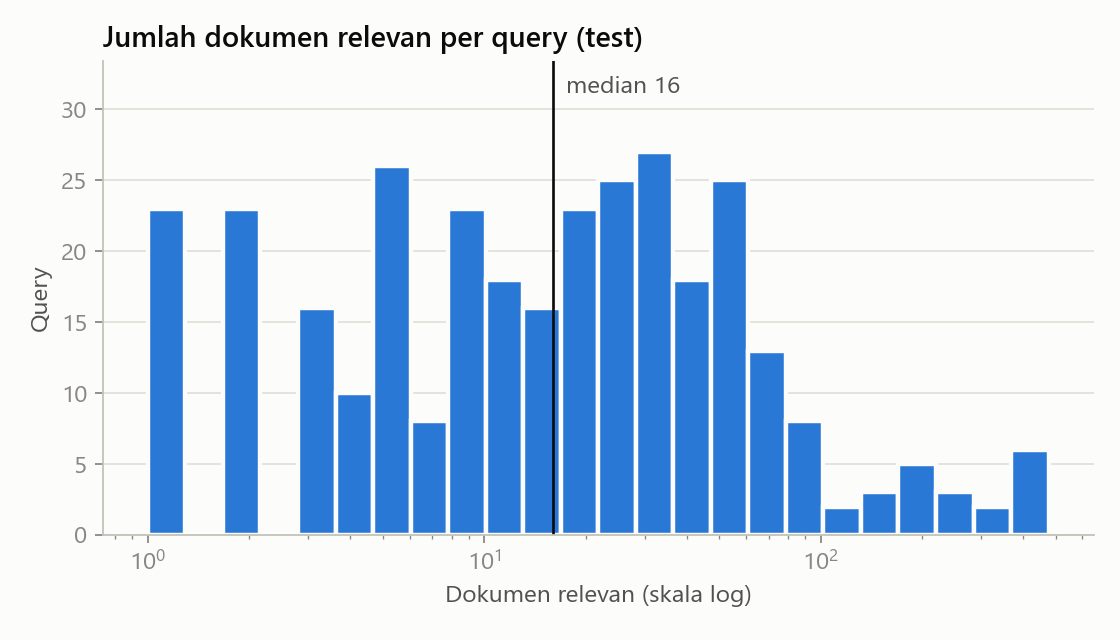

In [3]:
rows = []
for s, q in qrels.items():
    n = np.array([len(v) for v in q.values()])
    rows.append({'split': s, 'query': len(q), 'pasangan': int(n.sum()), 'rata2 relevan': round(n.mean(), 1), 'median': np.median(n),
                 'p90': round(np.percentile(n, 90), 1), 'maks': n.max(), 'query <5 relevan': int((n < 5).sum()),
                 'skor 2': sum(x == 2 for v in q.values() for x in v.values())})
display(pd.DataFrame(rows))
t = qrels['test']
print('Batas maksimum P@5 :', round(np.mean([min(len(v), 5) / 5 for v in t.values()]), 3))
print('Batas maksimum P@10:', round(np.mean([min(len(v), 10) / 10 for v in t.values()]), 3))
display(Image(FIG / 'eda_rel_per_query.png', width=560))

**Interpretasi:**
- Distribusinya sangat miring. Pada test, rata-rata 38,2 dokumen relevan per query tetapi mediannya hanya 16, dan ada query dengan sampai 475 dokumen relevan. Rata-rata saja menyesatkan, jadi median perlu ikut dilaporkan.
- 72 dari 323 query test punya kurang dari 5 dokumen relevan. Akibatnya P@5 sempurna pun hanya bisa mencapai **0,874** dan P@10 **0,775**, bukan 1,0.
- Skor 2 hanya ada di dev dan test (576 pasangan di test), sedangkan train seluruhnya skor 1. Karena itu fitur dari train memperlakukan relevansi sebagai biner, sementara nDCG tetap memakai skor bertingkat.

       query (kata)  dokumen (kata)
count        3237.0          3633.0
mean            3.3           233.8
std             2.5            83.4
min             1.0            17.0
25%             1.0           185.0
50%             2.0           237.0
75%             5.0           273.0
max            18.0          1481.0
Dokumen dengan teks kembar: 40 | query dengan teks kembar: 21


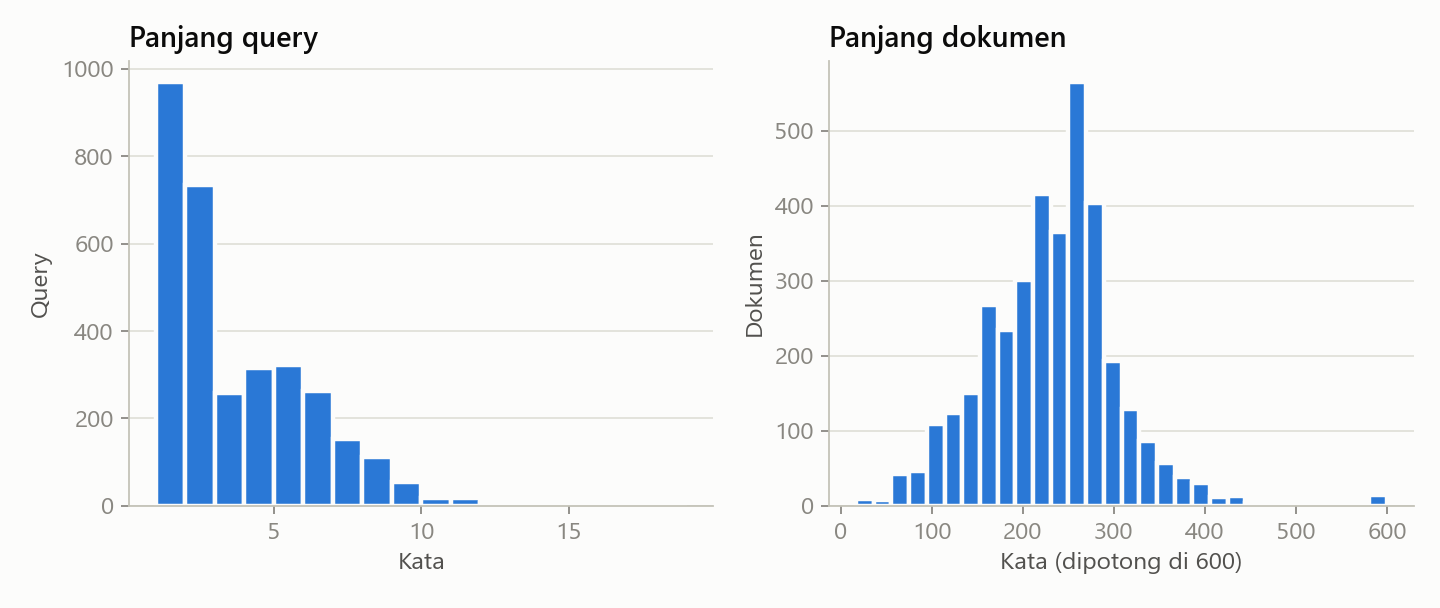

In [4]:
qlen = np.array([len(t.split()) for t in queries.values()])
dlen = np.array([len(d.split()) for d in docs])
print(pd.DataFrame({'query (kata)': pd.Series(qlen).describe(), 'dokumen (kata)': pd.Series(dlen).describe()}).round(1).to_string())
print('Dokumen dengan teks kembar:', len(docs) - len(set(docs)), '| query dengan teks kembar:', len(queries) - len(set(queries.values())))
display(Image(FIG / 'eda_lengths.png', width=700))

**Interpretasi:** Query sangat pendek (median 2 kata, rata-rata 3,3), sedangkan dokumen panjang (median 237 kata). Query sepanjang itu hanya memberi sedikit kata untuk dicocokkan, jadi satu kata yang berbeda istilah saja bisa membuat dokumen relevan terlewat. Ada juga 40 dokumen dengan teks kembar, yang bisa muncul sebagai hasil ganda di daftar peringkat.

Rata-rata porsi term query di dokumen relevan: 0.178
Dokumen relevan tanpa satu pun term query    : 69.2%


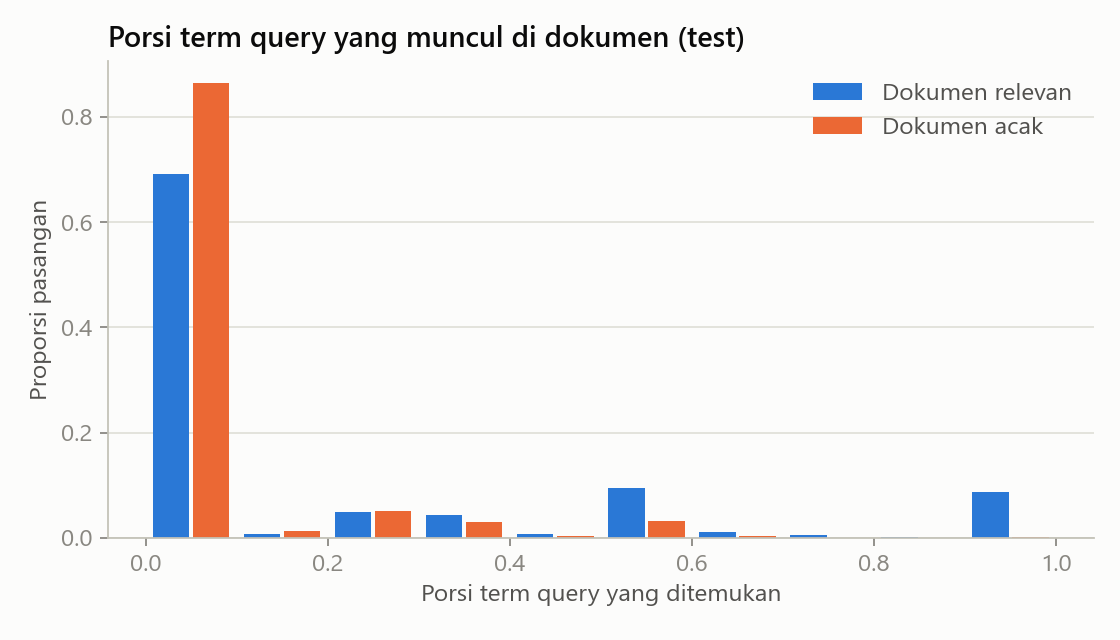

In [5]:
doc_toks = {d: set(analyze(t)) for d, t in zip(doc_ids, docs)}
rel, zero, total = [], 0, 0
for q, rels in qrels['test'].items():
    toks = set(analyze(queries[q]))
    if not toks: continue
    for d in rels:
        o = len(toks & doc_toks[d]) / len(toks); rel.append(o); zero += o == 0; total += 1
print(f'Rata-rata porsi term query di dokumen relevan: {np.mean(rel):.3f}')
print(f'Dokumen relevan tanpa satu pun term query    : {zero / total:.1%}')
display(Image(FIG / 'eda_lexical_gap.png', width=560))

**Interpretasi (temuan terpenting EDA):** **69,2% dokumen relevan tidak memuat satu pun kata dari query-nya**, dan rata-rata hanya 17,8% kata query muncul di dokumen relevan. TF-IDF dan BM25 hanya memberi skor pada dokumen yang memuat kata query, sehingga sebagian besar dokumen relevan nyaris mustahil naik ke atas. Inilah alasan utama precision temanmu tertahan di sekitar 0,3, bukan karena implementasinya salah. Solusinya harus bisa menjembatani istilah awam dan istilah medis.

Dokumen tanpa label train: 45 dari 3633 | median kemunculan: 27.0 | maks: 256
Dokumen relevan test yang pernah berlabel di train: 99.9%
Irisan ID query train-test: 0
Query test kembar dengan train (setelah stemming): 7 | Jaccard label: 0.4


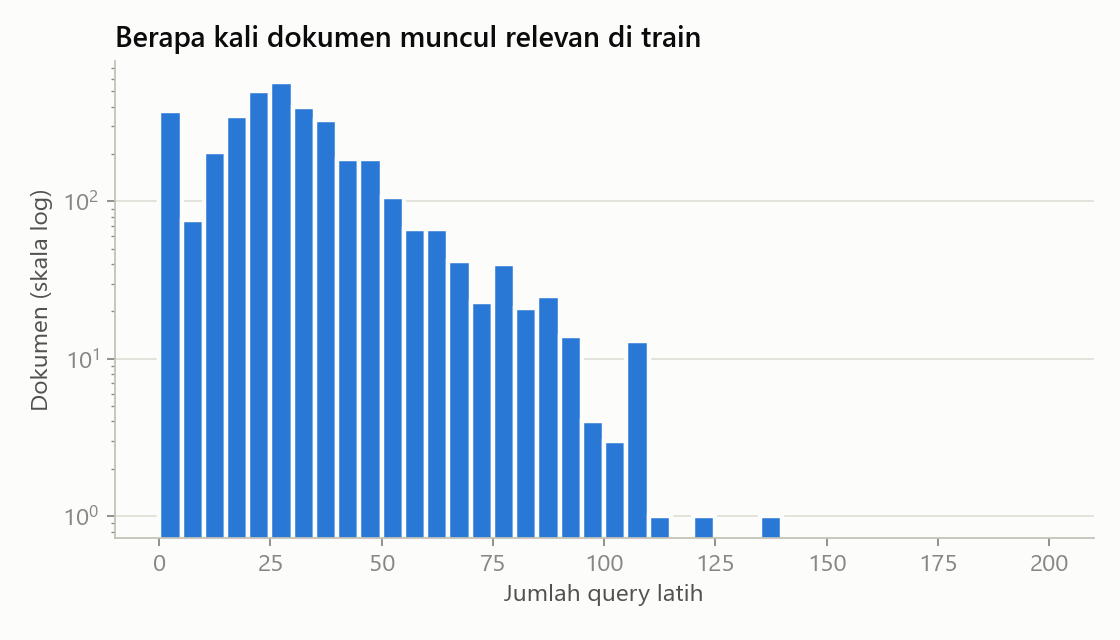

In [6]:
leak = json.load(open(RESULTS / 'leakage.json'))
pop = pd.Series([sum(d in v for v in qrels['train'].values()) for d in doc_ids])
seen = {d for v in qrels['train'].values() for d in v}
rel_test = [d for v in qrels['test'].values() for d in v]
print('Dokumen tanpa label train:', int((pop == 0).sum()), 'dari', len(pop), '| median kemunculan:', pop.median(), '| maks:', pop.max())
print(f'Dokumen relevan test yang pernah berlabel di train: {np.mean([d in seen for d in rel_test]):.1%}')
print('Irisan ID query train-test:', len(set(qrels['train']) & set(qrels['test'])))
print('Query test kembar dengan train (setelah stemming):', leak['test']['stem_dup_in_train'], '| Jaccard label:', round(leak['test']['stem_dup_mean_qrels_jaccard'], 2))
display(Image(FIG / 'eda_doc_popularity.png', width=560))

**Interpretasi:**
- 99,9% dokumen relevan di test pernah muncul sebagai dokumen relevan di train. Query berbeda, tapi kumpulan dokumennya sama, jadi label train bisa dimanfaatkan secara sah untuk memperkaya dokumen.
- Tidak ada ID query yang sama antara train dan test. Namun ada 7 query test (2,2%) yang teksnya kembar dengan query train setelah stemming. Label kembarannya hanya mirip sebagian (Jaccard 0,40). Risiko kebocorannya kecil, dan di bagian akhir hasilnya dihitung ulang tanpa 7 query ini.

## 4. Reproduksi baseline

In [7]:
index = LexicalIndex(docs)
lex = json.load(open(RESULTS / 'lexical.json')); tl = json.load(open(RESULTS / 'train_label.json'))
k1, b, rm = lex['bm25']['k1'], lex['bm25']['b'], lex['rm3']
top = lambda s, n=1000: [doc_ids[i] for i in np.argsort(-s)[:n]]
def report(fn):
    run = {q: fn(queries[q]) for q in qrels['test']}
    return run, evaluate(run, qrels['test'], log=False)
hasil = {}
run_tfidf, hasil['TF-IDF'] = report(lambda q: top(index.tfidf_scores(analyze(q))))
_, hasil['BM25 default (1.5, 0.75)'] = report(lambda q: top(index.bm25_scores(index.query_weights(q))))
run_bm25, hasil[f'BM25 tuned ({k1}, {b})'] = report(lambda q: top(index.bm25_scores(index.query_weights(q), k1, b)))
run_rm3, hasil['BM25 + RM3'] = report(lambda q: top(index.bm25_scores(index.rm3_weights(q, k1, b, rm['fb_docs'], rm['fb_terms'], rm['orig']), k1, b)))
print('Parameter RM3 terpilih di dev:', rm)
pd.DataFrame(hasil).T[['P@5','P@10','R@10','F1@10','nDCG@10','MAP']].round(4)

Parameter RM3 terpilih di dev: {'fb_docs': 10, 'fb_terms': 20, 'orig': 0.5}


,P@5,P@10,R@10,F1@10,nDCG@10,MAP
TF-IDF,0.3059,0.2328,0.1569,0.1253,0.3244,0.1543
"BM25 default (1.5, 0.75)",0.3077,0.2406,0.1559,0.1273,0.3294,0.1539
"BM25 tuned (1.5, 0.5)",0.3090,0.2412,0.1568,0.1281,0.3293,0.1540
BM25 + RM3,0.3245,0.2604,0.1750,0.1423,0.3504,0.1827


**Interpretasi:** Baseline berhasil direproduksi. P@5 BM25 sekitar **0,31** dan TF-IDF **0,306**, cocok dengan angka 0,3 yang didapat temanmu (proposal sendiri belum memuat hasil, jadi nilai K yang dia pakai perlu dipastikan).

Tuning `k1` dan `b` di dev hampir tidak mengubah hasil, jadi masalahnya bukan parameter BM25. RM3 (pseudo-relevance feedback) memberi kenaikan kecil ke P@5 0,3245 karena menambah kata dari dokumen teratas, tetapi tetap bergantung pada kata yang sudah cocok.

## 5. Metode tanpa label: embedding dan hybrid

In [8]:
q2i = {q: i for i, q in enumerate(queries)}
bge_q, bge_d = np.load(CACHE / 'bge-small_q.npy'), np.load(CACHE / 'bge-small_d.npy')
med_q, med_d = np.load(CACHE / 'medcpt_q.npy'), np.load(CACHE / 'medcpt_d.npy')
T = qrels['test']
run_bge = {q: top(bge_d @ bge_q[q2i[q]]) for q in T}
run_med = {q: top(med_d @ med_q[q2i[q]]) for q in T}
run_hybrid = {q: rrf([run_rm3[q], run_bge[q], run_med[q]]) for q in T}
tabel = {n: evaluate(r, T, log=False) for n, r in [('BGE-small', run_bge), ('MedCPT', run_med), ('Hybrid RRF', run_hybrid)]}
pd.DataFrame(tabel).T[['P@5','P@10','R@10','F1@10','nDCG@10','MAP']].round(4)

,P@5,P@10,R@10,F1@10,nDCG@10,MAP
BGE-small,0.3282,0.2576,0.1620,0.1359,0.3438,0.1701
MedCPT,0.3170,0.2461,0.1653,0.1342,0.3302,0.1694
Hybrid RRF,0.3498,0.2827,0.1851,0.1544,0.3756,0.2021


**Interpretasi:** Embedding tidak terlalu jauh dari BM25 kalau dipakai sendirian (BGE-small P@5 0,328, MedCPT 0,317). Model biomedis MedCPT juga tidak otomatis lebih baik, kemungkinan karena query NFCorpus berupa judul populer, sedangkan MedCPT dilatih dari pola pencarian di PubMed.

Yang lebih bermanfaat adalah **menggabungkan** keduanya. Hybrid RRF (BM25+RM3, BGE, MedCPT) mencapai P@5 **0,350**, naik 13% dari BM25, karena tiap metode menemukan dokumen relevan yang berbeda. Ini hasil terbaik yang tidak memakai label.

## 6. Memanfaatkan label train: expansion, kNN, co-citation

In [9]:
c = tl['expansion']; w = tl['combo']
sig = LabelSignals(docs, doc_ids, queries, qrels['train'], c['repeat'], c['k1'], c['b'])
def score_exp(q): return sig.expansion(q)
def score_combo(q):
    s = norm(sig.expansion(q))
    return s + w['w_knn'] * norm(sig.knn(q, w['n_knn'])) + w['w_co'] * norm(sig.cocite(s))
run_exp, m_exp = report(lambda q: top(score_exp(q)))
run_combo, m_combo = report(lambda q: top(score_combo(q)))
print('Parameter terpilih di dev:', c, w)
pd.DataFrame({'BM25 + document expansion': m_exp, 'Expansion + kNN + co-citation': m_combo}).T[['P@5','P@10','R@10','F1@10','nDCG@10','MAP']].round(4)

Parameter terpilih di dev: {'repeat': 2, 'k1': 1.5, 'b': 0.25} {'n_knn': 25, 'w_knn': 0.25, 'w_co': 0.25}


,P@5,P@10,R@10,F1@10,nDCG@10,MAP
BM25 + document expansion,0.3839,0.3201,0.2162,0.1759,0.4175,0.2670
Expansion + kNN + co-citation,0.4285,0.3687,0.2462,0.2078,0.4630,0.3454


**Interpretasi:** Lonjakan terbesar datang dari sini.
- **Document expansion** menambahkan teks query latih ke dokumen yang relevan untuk query tersebut, sehingga dokumen medis mendapat "kosakata awam". P@5 langsung naik ke **0,384**.
- **kNN query latih** mewariskan dokumen relevan dari query latih yang mirip, dan **co-citation** menaikkan dokumen yang sering relevan bersamaan. Gabungan ketiganya mencapai P@5 **0,4285** dan nDCG@10 **0,463**.

Metode ini langsung menyerang penyebab yang ditemukan di EDA, yaitu kesenjangan kata. Syaratnya, dokumen harus sudah punya label train, dan pada dataset ini syarat itu terpenuhi untuk 99,9% dokumen relevan test.

## 7. Perbandingan semua metode dan model akhir

,P@5,P@10,R@10,F1@10,nDCG@10,MAP,P@5 dev
Final stacking,0.4365,0.3728,0.2463,0.2088,0.4669,0.3100,0.4247
Expansion+kNN+Co-cite,0.4285,0.3687,0.2462,0.2078,0.4630,0.3454,0.4179
Hybrid RRF + label train,0.4248,0.3551,0.2340,0.1992,0.4508,0.2993,0.4111
Hybrid RRF (tanpa label),0.3498,0.2827,0.1851,0.1544,0.3756,0.2021,0.3605
Hybrid label + CE pretrained,0.3387,0.2759,0.1750,0.1477,0.3665,0.2598,0.3432
BGE-small,0.3282,0.2576,0.1620,0.1359,0.3438,0.1701,0.3321
BM25+RM3,0.3245,0.2604,0.1750,0.1423,0.3504,0.1827,0.3179
Hybrid + CE pretrained,0.3238,0.2548,0.1674,0.1370,0.3490,0.1927,0.3395
MedCPT,0.3170,0.2461,0.1653,0.1342,0.3302,0.1694,0.2932
BM25,0.3090,0.2412,0.1568,0.1281,0.3293,0.1540,0.2951


P@5 tanpa 7 query kembar:
{'BM25': 0.3063, 'Hybrid RRF (tanpa label)': 0.3475, 'Expansion+kNN+Co-cite': 0.4228, 'Final stacking': 0.4304}


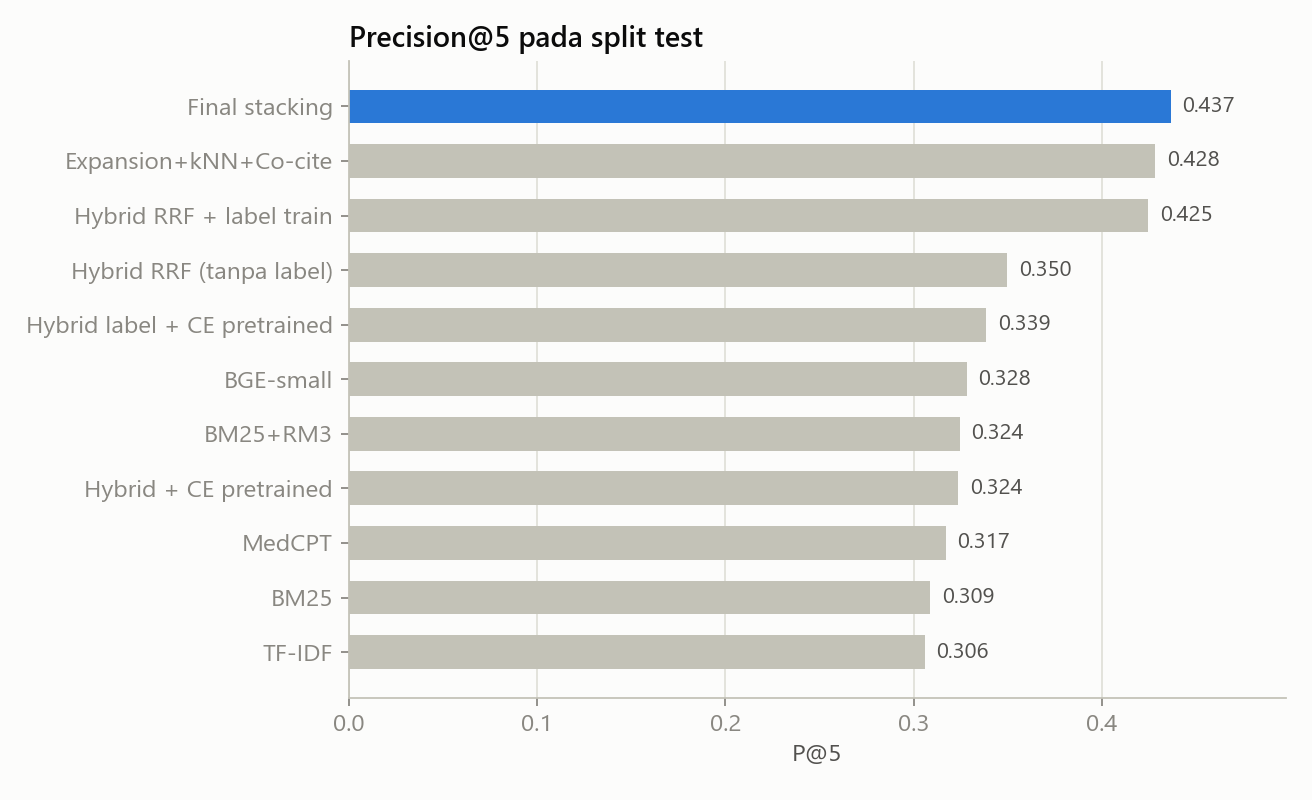

In [10]:
table = json.load(open(RESULTS / 'final_table.json'))
df = pd.DataFrame({n: v['test'] for n, v in table.items()}).T[['P@5','P@10','R@10','F1@10','nDCG@10','MAP']]
df['P@5 dev'] = [v['dev']['P@5'] for v in table.values()]
display(df.sort_values('P@5', ascending=False).round(4))
print('P@5 tanpa 7 query kembar:')
print({n: round(table[n]['test_tanpa_7_query_kembar']['P@5'], 4) for n in ['BM25', 'Hybrid RRF (tanpa label)', 'Expansion+kNN+Co-cite', 'Final stacking']})
display(Image(FIG / 'result_ladder_p5.png', width=660))

**Interpretasi:**
- **Model akhir** adalah penggabungan linear yang bobotnya dipilih lewat validasi silang 5-fold di dev (bobot: expansion 1, kNN 1, RRF 0,5, co-citation 0,25, RM3 0,25, cross-encoder 0,25). Hasil test: **P@5 0,4365, P@10 0,3728, nDCG@10 0,4669**, naik sekitar 41-55% dari BM25.
- Setelah 7 query kembar dibuang, P@5 tetap **0,4304**. Jadi kenaikannya bukan disebabkan oleh query kembar tersebut.
- **Cross-encoder pretrained justru menurunkan hasil bila dipakai sendiri** (hybrid 0,350 menjadi 0,324). Kemungkinan karena model ini dilatih untuk pencarian web tanya-jawab (MS MARCO), dan pada percobaan ini teksnya dipotong 128 token. Di model akhir bobotnya kecil.
- Dev dan test berperilaku serupa untuk tiap metode, jadi tidak terlihat tanda overfitting ke dev.
- Bila yang diprioritaskan MAP, pakai Expansion+kNN+Co-cite (0,345 vs 0,310). Model akhir hanya mengurutkan ulang 30 teratas, sedangkan sisa daftarnya berasal dari hybrid RRF.

## 8. Analisis kesalahan terhadap ground truth

         selisih rata2  CI95 bawah  CI95 atas    p Wilcoxon   naik  turun   sama
P@5           0.127554    0.100929   0.154799  2.459423e-16  127.0   27.0  169.0
P@10          0.131579    0.109907   0.153560  7.052544e-25  163.0   24.0  136.0
nDCG@10       0.137579    0.112339   0.163177  2.596304e-22  186.0   44.0   93.0
MAP           0.156001    0.133499   0.179116  1.492604e-41  275.0   24.0   24.0



Final vs Expansion+kNN+Co-cite (P@5): selisih 0.008 | p Wilcoxon 0.094


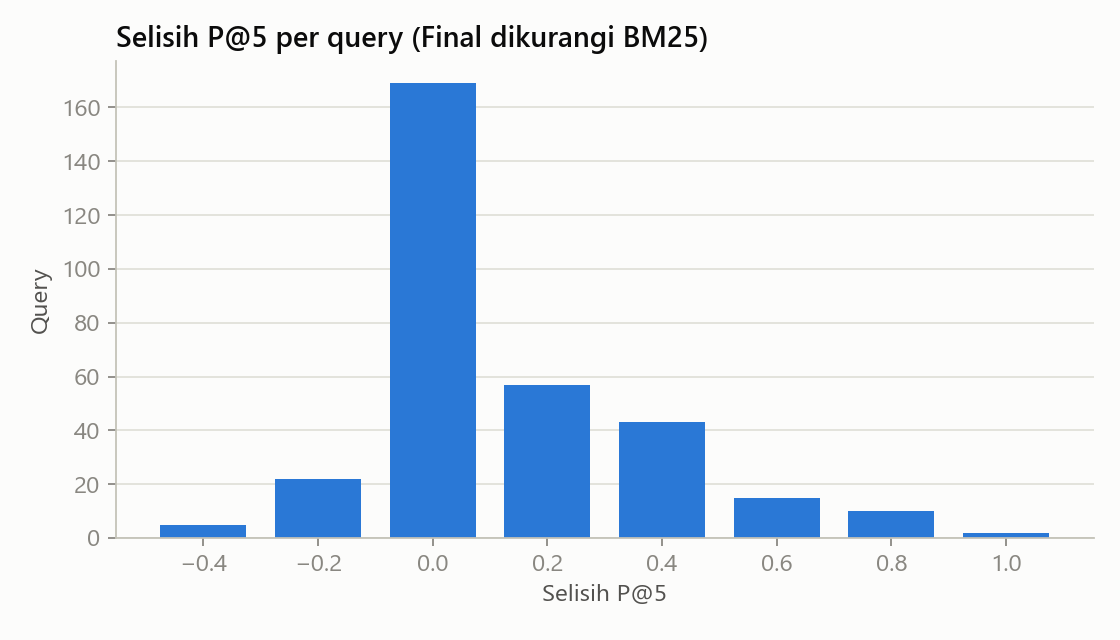

In [11]:
err = json.load(open(RESULTS / 'error_analysis.json'))
print(pd.DataFrame({k[6:]: {'selisih rata2': v['mean'], 'CI95 bawah': v['ci95'][0], 'CI95 atas': v['ci95'][1], 'p Wilcoxon': v['wilcoxon_p'],
                            'naik': v['better'], 'turun': v['worse'], 'sama': v['same']} for k, v in err.items() if k.startswith('delta_')}).T.to_string())
runs = pickle.load(open(CACHE / 'runs.pkl', 'rb'))['runs']
_, pa = evaluate(runs['Expansion+kNN+Co-cite'], T); _, pb = evaluate(runs['Final stacking'], T)
d = np.array([pb[q]['P@5'] - pa[q]['P@5'] for q in T])
print('\nFinal vs Expansion+kNN+Co-cite (P@5): selisih', round(d.mean(), 4), '| p Wilcoxon', round(stats.wilcoxon(d[d != 0]).pvalue, 3))
display(Image(FIG / 'err_delta_p5.png', width=560))

**Interpretasi:**
- Kenaikan dari BM25 **signifikan secara statistik**. Selisih P@5 rata-rata +0,128 (interval kepercayaan 95%: 0,101 sampai 0,155; p Wilcoxon sekitar 2e-16). Dari 323 query, 127 naik, 27 turun, dan 169 tetap.
- Namun model akhir **tidak signifikan lebih baik** dari Expansion+kNN+Co-cite (selisih P@5 +0,008; p = 0,094). Artinya, model sederhana itu sudah menangkap hampir semua kenaikan dan lebih mudah dijelaskan saat presentasi.


Jumlah dokumen relevan
           n  P@5 BM25  P@5 Final  nDCG@10 BM25  nDCG@10 Final
1-4     72.0     0.117      0.161         0.292          0.379
5-19   106.0     0.243      0.372         0.241          0.375
20-49   82.0     0.344      0.502         0.310          0.466
50+     63.0     0.594      0.775         0.546          0.723

Panjang query
              n  P@5 BM25  P@5 Final  nDCG@10 BM25  nDCG@10 Final
1 kata    103.0     0.351      0.482         0.384          0.526
2-3 kata   89.0     0.290      0.382         0.313          0.426
4-6 kata   96.0     0.279      0.429         0.287          0.440
7+ kata    35.0     0.314      0.463         0.326          0.469

Kemiripan kata query-relevan
            n  P@5 BM25  P@5 Final  nDCG@10 BM25  nDCG@10 Final
<10%    110.0     0.142      0.262         0.142          0.270
10-30%  127.0     0.369      0.524         0.336          0.509
30-60%   66.0     0.418      0.539         0.443          0.578
>=60%    20.0     0.490      0

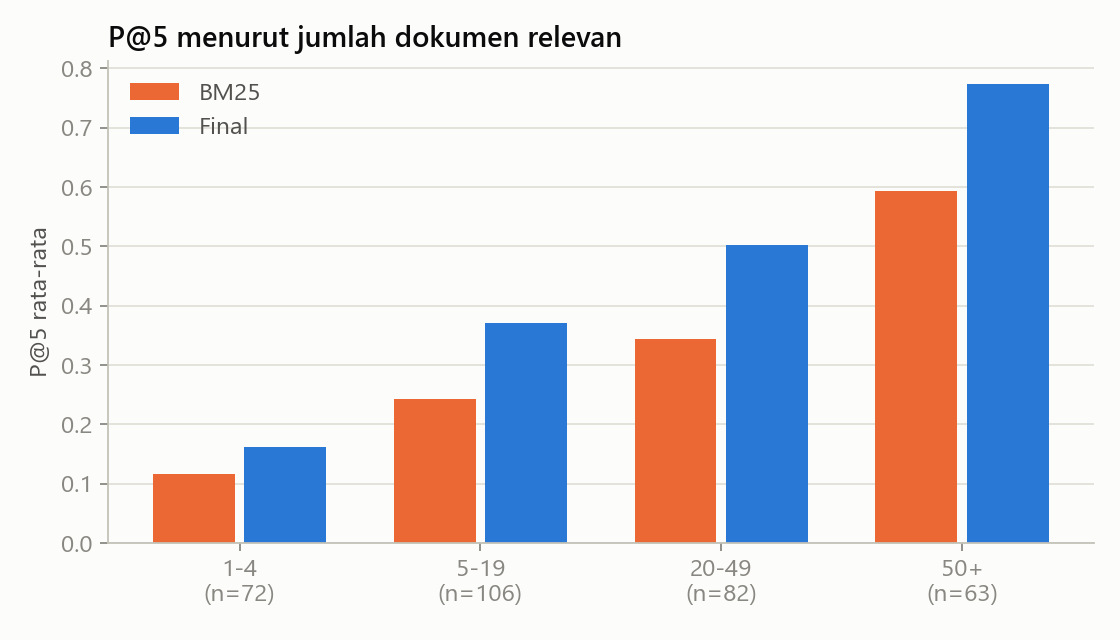

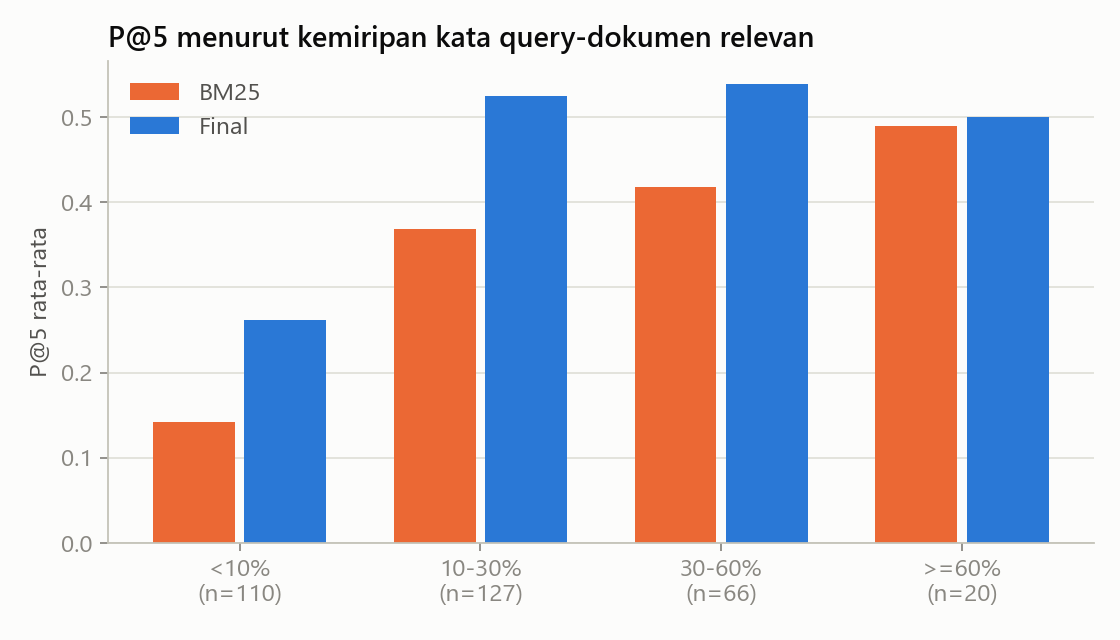

In [12]:
for key, ttl in [('by_n_relevant', 'Jumlah dokumen relevan'), ('by_query_length', 'Panjang query'), ('by_lexical_overlap', 'Kemiripan kata query-relevan')]:
    print('\n' + ttl); print(pd.DataFrame(err[key]).T.round(3).to_string())
display(Image(FIG / 'err_by_nrel.png', width=520)); display(Image(FIG / 'err_by_overlap.png', width=520))

**Interpretasi:**
- **Kesenjangan kata:** pada query dengan kemiripan kata di bawah 10%, P@5 naik hampir dua kali lipat (0,142 menjadi 0,262), tetapi kelompok ini tetap paling sulit. Pada query dengan kemiripan 60% ke atas (n=20) hampir tidak ada kenaikan (0,49 menjadi 0,50), dan nDCG@10 malah sedikit turun (0,938 menjadi 0,916). Metode leksikal sudah cukup untuk kelompok ini.
- **Jumlah relevan:** makin banyak dokumen relevan, makin mudah. P@5 mencapai 0,775 untuk query dengan 50+ dokumen relevan, tetapi hanya 0,161 untuk query dengan 1-4 dokumen relevan. Sebagian disebabkan batas maksimum P@5 yang memang rendah pada kelompok itu.
- **Panjang query:** model akhir unggul di semua panjang query, jadi perbaikannya tidak hanya berlaku untuk jenis query tertentu.

In [13]:
print('Query tanpa hit di top-5:', err['zero_hit_top5'])
print('Top-5 model akhir:', err['top5_final'])
print('Recall@100:', {k: round(v, 3) for k, v in err['recall_at_100'].items()})

Query tanpa hit di top-5: {'BM25': 111, 'Final': 95, 'both': 83}
Top-5 model akhir: {'true_positive': 705, 'false_positive': 910, 'tp_with_query_term': 0.8907801418439716, 'fp_with_query_term': 0.743956043956044, 'fp_duplicate_text_of_relevant_doc': 3}
Recall@100: {'BM25': 0.25, 'Final stacking': 0.515}


**Interpretasi:**
- Query tanpa satu pun dokumen relevan di top-5 turun dari 111 menjadi 95, tetapi **83 query gagal pada kedua model**. Ini batas nyata metode saat ini.
- Dari 1.615 slot top-5, 910 (56%) tidak ada di qrels. Sebanyak 74,4% di antaranya tetap memuat kata query, jadi topiknya sering dekat. Karena qrels tidak lengkap, sebagian "kesalahan" ini mungkin sebenarnya relevan. Dokumen kembar hanya menyumbang 3 kasus.
- Recall@100 naik dari 0,250 menjadi 0,515, sehingga tahap pencarian kandidat kini jauh lebih baik.

In [14]:
title = dict(zip(doc_ids, corpus['title']))
def banding(q):
    print(f'\n{q}: {queries[q]}  | dokumen relevan: {len(T[q])}')
    rows = [{'BM25': title[a][:62], 'GT': 'ya' if T[q].get(a) else '-', 'Final': title[b][:62], 'GT ': 'ya' if T[q].get(b) else '-'}
            for a, b in zip(runs['BM25'][q][:5], runs['Final stacking'][q][:5])]
    display(pd.DataFrame(rows, index=range(1, 6)))
for q in ['PLAIN-2670', 'PLAIN-2386', 'PLAIN-3342', 'PLAIN-1909', 'PLAIN-133']:
    banding(q)


PLAIN-2670: Is Caramel Color Carcinogenic?  | dokumen relevan: 35


,BM25,GT,Final,GT
1,Carcinogenicity and regulation of caramel colo...,ya,Carcinogenicity and regulation of caramel colo...,ya
2,Toxicology of food dyes.,-,TOXICITY AND CARCINOGENICITY STUDIES OF 4-METH...,ya
3,Polycyclic aromatic hydrocarbons (PAHs) in cof...,-,Does 4-methylimidazole have tumor preventive a...,ya
4,Facial Skin Coloration Affects Perceived Healt...,-,Synthetic Food Colors and Neurobehavioral Haza...,ya
5,You Are What You Eat: Within-Subject Increases...,-,Titanium Dioxide Nanoparticles in Food and Per...,ya



PLAIN-2386: worms  | dokumen relevan: 19


,BM25,GT,Final,GT
1,Anisakis simplex: from Obscure Infectious Worm...,-,Evaluation of a real-time polymerase chain rea...,ya
2,Comparative and meta-analytic insights into li...,-,Pictorial essay: Complications of a swallowed ...,ya
3,"A low-fat, whole-food vegan diet, as well as o...",-,Can ciguatera be a sexually transmitted disease?,ya
4,Cannabis and the lung.,-,Neurocysticercosis in pregnancy: not just anot...,ya
5,Esophageal injury by apple cider vinegar table...,-,Neurocysticercosis and oncogenesis.,ya



PLAIN-3342: Is Coconut Milk Good For You?  | dokumen relevan: 3


,BM25,GT,Final,GT
1,The cholesterol-lowering effect of coconut fla...,ya,"Effects of dietary coconut oil, butter and saf...",-
2,Dietary intake and the risk of coronary heart ...,ya,The intravenous use of coconut water.,-
3,Coconut oil enhances tomato carotenoid tissue ...,-,Coconut oil predicts a beneficial lipid profil...,-
4,Coconut oil predicts a beneficial lipid profil...,-,An Open-Label Pilot Study to Assess the Effica...,-
5,"Effects of dietary coconut oil, butter and saf...",-,Effects of dietary coconut oil on the biochemi...,-



PLAIN-1909: pork  | dokumen relevan: 463


,BM25,GT,Final,GT
1,"Beef, pork, and milk allergy (cross reactivity...",ya,Yersinia enterocolitica: a brief review of the...,ya
2,Pork intake and human papillomavirus-related d...,ya,Fresh meat and further processing characterist...,-
3,Transfer of methicillin-resistant Staphylococc...,ya,Effects of dietary factors and other metabolic...,-
4,From pig to pork: methicillin-resistant Staphy...,ya,Contamination of carcasses with human pathogen...,ya
5,Anaphylaxis to pork kidney is related to IgE a...,ya,Prevalence of Pathogenic Yersinia enterocoliti...,ya



PLAIN-133: Starving Tumors of Their Blood Supply  | dokumen relevan: 36


,BM25,GT,Final,GT
1,Nutrition of the intervertebral disc.,-,The flip side of immune surveillance: immune d...,-
2,The Collateral Network Concept: A Reassessment...,-,Expression of the biochemical defect of methio...,-
3,Diet and inflammation.,-,"Vegan proteins may reduce risk of cancer, obes...",-
4,Symptomatic disc herniation and serum lipid le...,-,"Effect of diet and exercise on serum insulin, ...",-
5,Potential of traditional ayurvedic formulation...,-,Immunological enhancement of breast cancer.,-


**Interpretasi (perbandingan dengan ground truth):**
- **Berhasil.** "Is Caramel Color Carcinogenic?" naik dari 1 menjadi 5 hit di top-5 karena model menemukan istilah *4-methylimidazole*. "worms" naik dari 0 menjadi 5 hit, termasuk dokumen *neurocysticercosis*. Model berhasil menghubungkan istilah awam dengan istilah medis.
- **Label tidak lengkap.** Pada "Is Coconut Milk Good For You?", kelima hasil model akhir membahas kelapa, tetapi semuanya dihitung salah karena qrels hanya punya 3 dokumen relevan. Skor 0 di sini belum tentu berarti hasilnya buruk.
- **Melenceng dari topik.** Pada "pork" (463 dokumen relevan), P@5 turun dari 1,0 menjadi 0,6 karena model bergeser ke topik pengolahan daging, yang dua dokumennya tidak ada di qrels.
- **Masih gagal.** "Starving Tumors of Their Blood Supply" butuh pemahaman bahwa frasa itu berarti *angiogenesis*. BM25 tersesat ke "blood supply" pada cakram tulang belakang, dan model akhir pun belum menemukannya.

## 9. Kesimpulan dan keterbatasan

**Kesimpulan**
1. Precision sekitar 0,3 disebabkan kesenjangan kata: 69% dokumen relevan tidak memuat kata dari query-nya.
2. Tanpa label, Hybrid RRF menaikkan P@5 ke 0,350.
3. Dengan label train, P@5 mencapai 0,437 (+41% dari BM25), dan kenaikannya signifikan.

**Keterbatasan yang perlu disebut saat presentasi**
- Metode berbasis label mensyaratkan dokumen sudah punya label train. Untuk dokumen yang benar-benar baru, hasilnya akan mendekati metode tanpa label.
- Qrels tidak lengkap, jadi sebagian dokumen yang dihitung salah mungkin sebenarnya relevan. P@5 juga dibatasi maksimum 0,874.
- Cross-encoder belum berhasil di-fine-tune: di CPU hanya 284 dari 6.276 langkah yang selesai dan loss masih 0,69, setara tebakan acak, sehingga model itu tidak dipakai. Skrip `04_finetune_ce.py` tersedia untuk dijalankan di GPU.
- Skor final diukur pada satu split test, dan rerank cross-encoder dibatasi pada 30 kandidat dengan teks 128 token karena keterbatasan CPU.